# Pronóstico mensual de tarifas spot de camión refrigerado por lane
### Entregable 4: Implementación, entrenamiento y evaluación del modelo

**Maestría en Inteligencia Artificial Aplicada**
Inteligencia Artificial y Aprendizaje Automático (TC4058.2)
**Equipo 1**

| Integrante | Matrícula |
|---|---|
| Jaime Martínez Vogel | A01283238 |
| Héctor de Luna Aguilar | A01610988 |

### Descripción del caso
Retomamos el caso del distribuidor de frutas y verduras frescas que mueve producto en camiones refrigerados y que necesita estimar cuánto le va a costar el flete spot el mes siguiente, tanto para armar su presupuesto como para decidir en qué momento le conviene más amarrar un contrato con un transportista. En el Entregable 3 obtuvimos, limpiamos y preparamos los datos de USDA y de la EIA, y en este entregable construimos el prototipo predictivo, lo comparamos contra una referencia simple y evaluamos si realmente aporta algo al negocio.

### Estructura del notebook
1. Bibliotecas y reproducibilidad
2. Definición del enfoque
3. Datos y variables
4. Partición de los datos
5. Modelos de referencia (baselines)
6. Modelo y entrenamiento
7. Validación cruzada temporal y selección del modelo
8. Evaluación final en el conjunto de prueba
9. Comparación, interpretación y utilidad para el negocio
10. Ejemplos de predicción y proyección a futuro
11. Conclusiones técnicas
12. Referencias

## 1. Bibliotecas y reproducibilidad

El notebook se probó con Python 3.11 y las versiones exactas de las bibliotecas están en "requirements.txt"; respecto al entregable anterior solo se agregó "scikit-learn". Para correrlo desde cero basta con:

```
pip install -r requirements.txt
```

El notebook lee los archivos que generó el Entregable 3 ("data/processed/lanes_modelo.csv" y "data/raw/eia_diesel_semanal_raw.xls") con rutas relativas, por lo que funciona en cualquier computadora sin cambiar nada y sin conexión a internet. Fijamos una semilla para que los resultados se puedan repetir.

In [1]:
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

SEMILLA = 42
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)

Python: 3.11.18
pandas: 2.3.3 | numpy: 2.4.6 | scikit-learn: 1.9.1


## 2. Definición del enfoque

La pregunta de negocio sigue siendo la misma: **¿cuál será la tarifa spot (USD por carga) del mes siguiente para cada lane?** Se trata de un problema de **pronóstico**, que resolvemos como una regresión con rezagos sobre un panel de 94 lanes, donde cada renglón es una lane en un mes y todas las entradas son información que ya se conoce al cerrar el mes anterior.

| Elemento | Definición |
|---|---|
| Variable objetivo | "tarifa": mediana mensual del "midpoint" de USDA por lane, en USD por carga |
| Lo que predice el modelo | "cambio_lane": el cambio logarítmico de la tarifa contra el mes anterior, que después se convierte a USD |
| Predictoras | Cambios recientes de la lane y del mercado, estacionalidad, cambio del diésel, disponibilidad de camiones y distancia (sección 3.2) |
| Tipo de problema | Pronóstico de series de tiempo (regresión con rezagos) |
| Algoritmo principal | HistGradientBoostingRegressor de scikit-learn con pérdida de error absoluto |
| Referencias | Baseline ingenuo, baseline estacional, media de entrenamiento y una regresión Ridge |

**¿Por qué predecir el cambio y no la tarifa directamente?** En el E3 vimos que el mercado tiene una tendencia creciente con saltos de nivel muy marcados y que en 2026 las tarifas están subiendo a niveles que casi no existen en la historia. Los modelos de árboles no pueden predecir valores fuera del rango que vieron al entrenar, ya que cada hoja regresa un promedio de casos pasados, lo cual hace que si el modelo aprende la tarifa en niveles se quede "atorado" en los precios viejos. En cambio, si aprende el cambio porcentual contra el mes anterior, el nivel lo pone la tarifa más reciente y el modelo solo tiene que decidir si la tarifa sube o baja y cuánto, algo que sí se repite a lo largo de los años. En la sección 7 comprobamos esto con el mismo algoritmo entrenado en niveles.

**¿Por qué Gradient Boosting?** Porque la relación entre las entradas y el cambio de la tarifa no es lineal y depende de combinaciones, por ejemplo el efecto de la temporada no es el mismo en una lane corta que en una larga, y los árboles capturan esas interacciones sin que las tengamos que programar. Elegimos la versión "HistGradientBoostingRegressor" porque es rápida con miles de renglones y porque permite usar la pérdida de error absoluto, que coincide con nuestra métrica principal (MAE) y es menos sensible a los meses de choque, ya que no eleva los errores al cuadrado. Como referencia lineal y más sencilla entrenamos también una regresión Ridge con las mismas entradas.

## 3. Datos y variables

### 3.1 Carga de los datos preparados en el Entregable 3
Usamos el archivo "lanes_modelo.csv", que tiene las 94 lanes activas con al menos 36 meses de historia, y el archivo semanal del diésel de la EIA, que convertimos a promedio mensual. Solo conservamos las columnas originales porque los rezagos los volvemos a construir aquí con la misma lógica del E3, agregando algunos nuevos.

In [2]:
CARPETA_PROC = "data/processed"
ARCHIVO_DIESEL = "data/raw/eia_diesel_semanal_raw.xls"

base = pd.read_csv(f"{CARPETA_PROC}/lanes_modelo.csv")
base["mes"] = pd.PeriodIndex(base["mes"], freq="M")

# Nos quedamos con las columnas originales; los rezagos los volvemos a construir aquí
base = base[["origin", "destination", "lane", "mes", "tarifa", "disponibilidad", "distancia"]]
print(f"Lane-meses: {len(base):,} | lanes: {base['lane'].nunique()} | de {base['mes'].min()} a {base['mes'].max()}")
base.head()

Lane-meses: 14,004 | lanes: 94 | de 2000-01 a 2026-10


,origin,destination,lane,mes,tarifa,disponibilidad,distancia
0,CENTRAL AND SOUTH FLORIDA,ATLANTA,CENTRAL AND SOUTH FLORIDA → ATLANTA,2003-11,845.00,3.00,510.00
1,CENTRAL AND SOUTH FLORIDA,ATLANTA,CENTRAL AND SOUTH FLORIDA → ATLANTA,2003-12,950.00,3.80,510.00
2,CENTRAL AND SOUTH FLORIDA,ATLANTA,CENTRAL AND SOUTH FLORIDA → ATLANTA,2004-01,940.00,3.27,510.00
3,CENTRAL AND SOUTH FLORIDA,ATLANTA,CENTRAL AND SOUTH FLORIDA → ATLANTA,2004-02,950.00,2.75,510.00
4,CENTRAL AND SOUTH FLORIDA,ATLANTA,CENTRAL AND SOUTH FLORIDA → ATLANTA,2004-03,950.00,3.00,510.00


In [3]:
# Diésel: promedio mensual a partir del archivo semanal de la EIA que descargamos en el E3
diesel_raw = pd.read_excel(ARCHIVO_DIESEL, sheet_name="Data 1", skiprows=2).iloc[:, :2]
diesel_raw.columns = ["fecha", "diesel"]
diesel_raw["fecha"] = pd.to_datetime(diesel_raw["fecha"], errors="coerce")
diesel_raw["diesel"] = pd.to_numeric(diesel_raw["diesel"], errors="coerce")
diesel_raw = diesel_raw.dropna()

ULTIMO_MES = base["mes"].max()
diesel_mensual = diesel_raw.groupby(diesel_raw["fecha"].dt.to_period("M"))["diesel"].mean()
diesel_mensual = diesel_mensual[diesel_mensual.index <= ULTIMO_MES].rename_axis("mes").reset_index()
diesel_mensual.tail(3)

,mes,diesel
389,2026-08,5.46
390,2026-09,6.29
391,2026-10,6.25


### 3.2 Construcción de las variables

Todas las variables se calculan con una sola función, "crear_variables", para que el entrenamiento, la prueba y la proyección a futuro usen exactamente la misma lógica. Los rezagos se construyen moviendo el mes y uniendo por lane, igual que en el E3, de modo que si un mes no existe el rezago queda vacío en lugar de tomar el valor de otro mes.

| Variable | Qué mide | Por qué ayuda | ¿Se conoce al pronosticar? |
|---|---|---|---|
| "cambio_lane_lag1" | Cambio de la lane entre los dos meses anteriores | Captura la inercia o el rebote del movimiento más reciente | Sí, ambos meses ya cerraron |
| "cambio_lane_hace12" | Cambio que tuvo la lane en la misma transición del año pasado | Es la estacionalidad propia de la lane (por ejemplo, el arranque de temporada de un origen) | Sí |
| "cambio_mercado_lag1" | Cambio promedio de las 94 lanes el mes anterior | Indica si todo el mercado viene subiendo o bajando | Sí |
| "cambio_mercado_hace12" | Cambio promedio del mercado en la misma transición del año pasado | Estacionalidad general del mercado | Sí |
| "cambio_diesel_lag1" | Cambio del precio promedio del diésel el mes anterior | Es uno de los principales costos del transporte | Sí |
| "disponibilidad_lag1" | Disponibilidad de camiones del mes anterior (1 = sobrada, 5 = escasa) | La escasez de camiones puede anticipar alzas | Sí |
| "distancia" | Millas de la lane | Las lanes cortas y largas reaccionan distinto en porcentaje | Sí, es fija |
| "mes_sin" y "mes_cos" | Mes del año en forma cíclica | Para que diciembre y enero queden "cerca" | Sí, es el calendario |

Comparado con la propuesta del E3, cambiamos los niveles ("tarifa_lag1", "tarifa_lag12", "diesel_lag1" y "anio") por sus cambios porcentuales, ya que el modelo ahora predice un cambio y los niveles harían que volviera a depender de precios que no se repiten; además, dejamos fuera "origin" y "destination" porque la distancia y la estacionalidad propia de cada lane ya capturan su comportamiento y así el modelo podría funcionar también con lanes que tengan poca historia.

In [4]:
def agregar_rezago(tabla, columna, meses):
    # Igual que en el E3: se mueve el mes y se une por lane y mes, así un mes faltante deja el rezago vacío
    anterior = tabla[["lane", "mes", columna]].copy()
    anterior["mes"] = anterior["mes"] + meses
    anterior = anterior.rename(columns={columna: f"{columna}_lag{meses}"})
    return tabla.merge(anterior, on=["lane", "mes"], how="left")


def agregar_por_mes(tabla, serie_mensual, columna, nombre, meses):
    # Une una serie que es igual para todas las lanes (mercado o diésel) con N meses de rezago
    anterior = serie_mensual[["mes", columna]].copy()
    anterior["mes"] = anterior["mes"] + meses
    anterior = anterior.rename(columns={columna: nombre})
    return tabla.merge(anterior, on="mes", how="left")


def crear_variables(panel, diesel_mensual):
    tabla = panel.copy()
    for meses in [1, 2, 12, 13]:
        tabla = agregar_rezago(tabla, "tarifa", meses)
    tabla = agregar_rezago(tabla, "disponibilidad", 1)

    # Target del modelo: cambio logarítmico contra el mes anterior
    tabla["cambio_lane"] = np.log(tabla["tarifa"] / tabla["tarifa_lag1"])

    # Mercado: promedio del cambio de todas las lanes en cada mes
    mercado = tabla.groupby("mes")["cambio_lane"].mean().reset_index(name="cambio_mercado")
    tabla = agregar_por_mes(tabla, mercado, "cambio_mercado", "cambio_mercado_lag1", 1)
    tabla = agregar_por_mes(tabla, mercado, "cambio_mercado", "cambio_mercado_hace12", 12)

    # Diésel: cambio del mes anterior contra el que le precede
    diesel = diesel_mensual.copy()
    diesel["cambio_diesel"] = np.log(diesel["diesel"] / diesel["diesel"].shift(1))
    tabla = agregar_por_mes(tabla, diesel, "cambio_diesel", "cambio_diesel_lag1", 1)

    # Variables de la propia lane, todas con información que ya se conoce al pronosticar
    tabla["cambio_lane_lag1"] = np.log(tabla["tarifa_lag1"] / tabla["tarifa_lag2"])
    tabla["cambio_lane_hace12"] = np.log(tabla["tarifa_lag12"] / tabla["tarifa_lag13"])
    tabla["mes_sin"] = np.sin(2 * np.pi * tabla["mes"].dt.month / 12)
    tabla["mes_cos"] = np.cos(2 * np.pi * tabla["mes"].dt.month / 12)
    return tabla.sort_values(["mes", "lane"]).reset_index(drop=True)


ENTRADAS = ["cambio_lane_lag1", "cambio_lane_hace12", "cambio_mercado_lag1", "cambio_mercado_hace12",
            "cambio_diesel_lag1", "disponibilidad_lag1", "distancia", "mes_sin", "mes_cos"]
TARGET = "cambio_lane"

panel = crear_variables(base, diesel_mensual)
panel[["lane", "mes", "tarifa", "tarifa_lag1", TARGET] + ENTRADAS].tail(3)

,lane,mes,tarifa,tarifa_lag1,cambio_lane,cambio_lane_lag1,cambio_lane_hace12,cambio_mercado_lag1,cambio_mercado_hace12,cambio_diesel_lag1,disponibilidad_lag1,distancia,mes_sin,mes_cos
14001,"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGT...",2026-10,"12,200.00","10,450.00",0.15,0.13,0.04,0.01,0.01,0.14,4.80,"2,750.00",-0.87,0.50
14002,"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGT...",2026-10,"11,350.00","10,150.00",0.11,0.18,0.02,0.01,0.01,0.14,4.80,"2,700.00",-0.87,0.50
14003,"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGT...",2026-10,"1,462.50","1,300.00",0.12,0.12,0.05,0.01,0.01,0.14,4.80,140.00,-0.87,0.50


### 3.3 Revisión de fuga de información

Antes de entrenar hacemos dos revisiones automáticas: que los rezagos que reconstruimos sean idénticos a los del E3 y que el cambio de mercado que recibe un mes venga únicamente del mes anterior. Las variables "weeklow", "weekhigh" y "rpm" del mismo mes siguen fuera del modelo por la fuga que demostramos en el E3.

In [5]:
# Revisión 1: los rezagos de la tarifa deben coincidir con los del E3
e3 = pd.read_csv(f"{CARPETA_PROC}/lanes_modelo.csv")
e3["mes"] = pd.PeriodIndex(e3["mes"], freq="M")
revision = panel.merge(e3[["lane", "mes", "tarifa_lag1", "tarifa_lag12"]], on=["lane", "mes"], suffixes=("", "_e3"))
print("¿tarifa_lag1 igual al E3?", np.allclose(revision["tarifa_lag1"], revision["tarifa_lag1_e3"], equal_nan=True))
print("¿tarifa_lag12 igual al E3?", np.allclose(revision["tarifa_lag12"], revision["tarifa_lag12_e3"], equal_nan=True))

# Revisión 2: el cambio de mercado de un mes debe venir SOLO del mes anterior
mes_revision = pd.Period("2025-06", freq="M")
esperado = panel.loc[panel["mes"] == mes_revision - 1, "cambio_lane"].mean()
usado = panel.loc[panel["mes"] == mes_revision, "cambio_mercado_lag1"].iloc[0]
print(f"cambio_mercado_lag1 de {mes_revision}: {usado:.5f} | promedio real de {mes_revision - 1}: {esperado:.5f}")

¿tarifa_lag1 igual al E3? True
¿tarifa_lag12 igual al E3? True
cambio_mercado_lag1 de 2025-06: 0.05511 | promedio real de 2025-05: 0.05511


## 4. Partición de los datos

Mantenemos la división cronológica del E3, con la diferencia de que ahora el entrenamiento (2000 a 2023) y la validación (2024) forman un solo **conjunto de desarrollo**, porque en lugar de una sola validación aplicamos validación cruzada temporal, que es más confiable. La **prueba final** sigue siendo de enero de 2025 a octubre de 2026 y no se usa para ninguna decisión, solo para medir el modelo ya seleccionado una sola vez.

Quitamos las filas que no tienen tarifa del mes anterior, ya que sin ella no existe el baseline ni el cambio que predecimos; de esta forma todos los modelos se evalúan exactamente sobre los mismos renglones.

In [6]:
# Solo filas con tarifa del mes anterior: sin ella no existe el baseline ni el cambio que predecimos
datos = panel.dropna(subset=["tarifa", "tarifa_lag1"]).reset_index(drop=True)

FIN_DESARROLLO = pd.Period("2024-12", freq="M")
desarrollo = datos[datos["mes"] <= FIN_DESARROLLO].reset_index(drop=True)
prueba = datos[datos["mes"] > FIN_DESARROLLO].reset_index(drop=True)

resumen = pd.DataFrame({
    "filas": [len(desarrollo), len(prueba)],
    "lanes": [desarrollo["lane"].nunique(), prueba["lane"].nunique()],
    "desde": [desarrollo["mes"].min(), prueba["mes"].min()],
    "hasta": [desarrollo["mes"].max(), prueba["mes"].max()],
}, index=["desarrollo (entrenamiento + validación cruzada)", "prueba final"])
print(f"Filas sin tarifa del mes anterior que se quitan: {len(panel.dropna(subset=['tarifa'])) - len(datos):,}")
resumen

Filas sin tarifa del mes anterior que se quitan: 1,154


,filas,lanes,desde,hasta
desarrollo (entrenamiento + validación cruzada),11604,94,2000-02,2024-12
prueba final,1246,94,2025-01,2026-10


In [7]:
# Validación cruzada temporal: TimeSeriesSplit sobre los MESES y no sobre las filas,
# para que un mismo mes nunca quede repartido entre entrenamiento y validación
meses_desarrollo = np.sort(desarrollo["mes"].unique())
divisor = TimeSeriesSplit(n_splits=5, test_size=12)

folds = []
tabla_folds = []
for numero, (idx_ent, idx_val) in enumerate(divisor.split(meses_desarrollo), start=1):
    meses_ent, meses_val = meses_desarrollo[idx_ent], meses_desarrollo[idx_val]
    filas_ent = desarrollo.index[desarrollo["mes"].isin(meses_ent)]
    filas_val = desarrollo.index[desarrollo["mes"].isin(meses_val)]
    folds.append((filas_ent, filas_val))
    tabla_folds.append({"fold": numero, "entrena": f"{meses_ent[0]} a {meses_ent[-1]}", "valida": f"{meses_val[0]} a {meses_val[-1]}",
                        "filas_entrena": len(filas_ent), "filas_valida": len(filas_val)})
pd.DataFrame(tabla_folds).set_index("fold")

,entrena,valida,filas_entrena,filas_valida
fold,,,,
1,2000-02 a 2019-12,2020-01 a 2020-12,8248,565
2,2000-02 a 2020-12,2021-01 a 2021-12,8813,634
3,2000-02 a 2021-12,2022-01 a 2022-12,9447,666
4,2000-02 a 2022-12,2023-01 a 2023-12,10113,732
5,2000-02 a 2023-12,2024-01 a 2024-12,10845,759


## 5. Modelos de referencia (baselines)

Definimos tres referencias simples. La principal es el **baseline ingenuo**, que repite la tarifa del mes anterior y es la referencia que sugieren las instrucciones para pronósticos; en el E3 vimos que es muy fuerte, ya que la tarifa de un mes y la del siguiente tienen una correlación de 0.98. Como segunda referencia usamos el **baseline estacional**, que repite la tarifa del mismo mes del año anterior, y como tercera la **media de entrenamiento**, que es la referencia típica de una regresión y nos sirve para dimensionar cuánto aporta usar la historia de cada lane.

In [8]:
def baseline_ingenuo(tabla):
    # Persistencia: el mes siguiente cuesta lo mismo que este mes
    return tabla["tarifa_lag1"].to_numpy()


def baseline_estacional(tabla):
    # Mismo mes del año anterior; si no existe, se usa el mes anterior
    return tabla["tarifa_lag12"].fillna(tabla["tarifa_lag1"]).to_numpy()


def baseline_media(entrenamiento, tabla):
    # Promedio de la tarifa calculado SOLO con entrenamiento
    return np.full(len(tabla), entrenamiento["tarifa"].mean())

## 6. Modelo y entrenamiento

El modelo se arma como un **Pipeline** que primero imputa los faltantes con la mediana y agrega una columna indicadora de faltante, después escala las variables y al final entrena el modelo. Como todo está dentro del pipeline, cada vez que se entrena (en cada fold de la validación cruzada y en el entrenamiento final) la mediana y el escalamiento se calculan solo con los datos de entrenamiento de ese momento, lo cual evita la fuga de información. Los faltantes vienen principalmente de "cambio_lane_hace12" (2,187 renglones) y "cambio_lane_lag1" (1,096), ya que algunas lanes son estacionales y no tienen dato en todos los meses.

Los parámetros principales del Gradient Boosting son los siguientes: "loss='absolute_error'" hace que el modelo minimice el error absoluto, igual que nuestra métrica principal; "learning_rate=0.05" y "max_iter=200" indican que se construyen 200 árboles pequeños y que cada uno corrige solo el 5% del error que dejaron los anteriores, lo cual lo hace más estable; "max_leaf_nodes=31" limita el tamaño de cada árbol, y "min_samples_leaf" pide un mínimo de lane-meses por hoja para que el modelo no aprenda reglas basadas en pocos casos. Este último es el único parámetro que probamos con tres valores (20, 60 y 150), ya que las instrucciones no piden una búsqueda exhaustiva. Por último, "early_stopping=False" evita que el modelo separe internamente una validación al azar, lo cual rompería el orden temporal.

La predicción final en USD se obtiene como la tarifa del mes anterior multiplicada por la exponencial del cambio predicho, por lo que si el modelo predice un cambio de 0 su pronóstico es igual al del baseline ingenuo.

In [9]:
def crear_preprocesamiento():
    # Se ajusta dentro del pipeline, así la mediana y el escalamiento salen solo del entrenamiento de cada fold
    numericas = Pipeline([
        ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalar", StandardScaler()),
    ])
    return ColumnTransformer([("num", numericas, ENTRADAS)])


def crear_modelo_hgb(min_samples_leaf=60):
    return Pipeline([
        ("prep", crear_preprocesamiento()),
        ("modelo", HistGradientBoostingRegressor(
            loss="absolute_error",      # optimiza el error absoluto, igual que la métrica principal (MAE)
            learning_rate=0.05,         # cada árbol corrige solo una parte del error, para no sobreajustar
            max_iter=200,               # número de árboles
            max_leaf_nodes=31,          # tamaño máximo de cada árbol
            min_samples_leaf=min_samples_leaf,  # mínimo de lane-meses por hoja, evita reglas basadas en pocos casos
            early_stopping=False,       # sin separación aleatoria interna, para respetar el orden temporal
            random_state=SEMILLA,
        )),
    ])


def crear_modelo_ridge():
    return Pipeline([("prep", crear_preprocesamiento()), ("modelo", Ridge(alpha=1.0))])


def a_tarifa(tabla, cambio_predicho):
    # El modelo predice el cambio; la tarifa se reconstruye a partir de la tarifa del mes anterior
    return tabla["tarifa_lag1"].to_numpy() * np.exp(cambio_predicho)


crear_modelo_hgb()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differ

In [10]:
# Comparación de control: el mismo algoritmo, pero prediciendo la tarifa en niveles con las variables del E3
ENTRADAS_E3 = ["tarifa_lag1", "tarifa_lag12", "disponibilidad_lag1", "distancia", "mes_sin", "mes_cos"]


def crear_modelo_niveles():
    prep = ColumnTransformer([("num", Pipeline([("imputar", SimpleImputer(strategy="median", add_indicator=True)),
                                                ("escalar", StandardScaler())]), ENTRADAS_E3)])
    return Pipeline([("prep", prep), ("modelo", HistGradientBoostingRegressor(
        loss="absolute_error", learning_rate=0.05, max_iter=200, min_samples_leaf=60,
        early_stopping=False, random_state=SEMILLA))])

## 7. Validación cruzada temporal y selección del modelo

Usamos "TimeSeriesSplit" con 5 divisiones de 12 meses cada una (sección 4), de modo que cada fold entrena con todo lo anterior a un año y valida en ese año completo: 2020, 2021, 2022, 2023 y 2024. Lo aplicamos sobre los meses y no sobre los renglones, porque si lo aplicáramos sobre los renglones un mismo mes podría quedar repartido entre entrenamiento y validación y el modelo vería lanes de un mes para predecir otras lanes de ese mismo mes. Todos los candidatos se evalúan con los mismos folds y las mismas métricas, y el modelo final se elige con el menor MAE promedio de la validación cruzada, sin ver la prueba.

In [11]:
def wape(real, pred):
    return np.abs(real - pred).sum() / np.abs(real).sum()


def metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "WAPE": wape(real, pred),
            "R2": r2_score(real, pred)}


def predecir(nombre, ent, val):
    if nombre == "Baseline ingenuo (mes anterior)":
        return baseline_ingenuo(val)
    if nombre == "Baseline estacional (hace 12 meses)":
        return baseline_estacional(val)
    if nombre == "Baseline media de entrenamiento":
        return baseline_media(ent, val)
    if nombre == "HGB en niveles (variables del E3)":
        return crear_modelo_niveles().fit(ent[ENTRADAS_E3], ent["tarifa"]).predict(val[ENTRADAS_E3])
    if nombre == "Ridge (cambio)":
        modelo = crear_modelo_ridge()
    else:  # "HGB (cambio) hoja=N"
        modelo = crear_modelo_hgb(int(nombre.split("=")[1]))
    modelo.fit(ent[ENTRADAS], ent[TARGET])
    return a_tarifa(val, modelo.predict(val[ENTRADAS]))


CANDIDATOS = ["Baseline ingenuo (mes anterior)", "Baseline estacional (hace 12 meses)", "Baseline media de entrenamiento",
              "Ridge (cambio)", "HGB en niveles (variables del E3)",
              "HGB (cambio) hoja=20", "HGB (cambio) hoja=60", "HGB (cambio) hoja=150"]

resultados_cv = []
for nombre in CANDIDATOS:
    for fold, (filas_ent, filas_val) in enumerate(folds, start=1):
        ent, val = desarrollo.loc[filas_ent], desarrollo.loc[filas_val]
        fila = metricas(val["tarifa"].to_numpy(), predecir(nombre, ent, val))
        fila.update({"modelo": nombre, "fold": fold, "anio_validado": str(val["mes"].min().year)})
        resultados_cv.append(fila)
resultados_cv = pd.DataFrame(resultados_cv)

tabla_cv = resultados_cv.groupby("modelo")[["MAE", "RMSE", "WAPE"]].agg(["mean", "std"]).sort_values(("MAE", "mean"))
tabla_cv

MAE            RMSE        WAPE     
                                        mean    std     mean    std mean  std
modelo                                                                       
HGB (cambio) hoja=20                  289.67  42.56   422.43  55.77 0.05 0.00
HGB (cambio) hoja=150                 291.49  48.72   424.61  64.66 0.05 0.01
HGB (cambio) hoja=60                  291.89  43.20   428.26  56.57 0.05 0.00
Baseline ingenuo (mes anterior)       300.47  49.11   459.33  65.91 0.05 0.01
Ridge (cambio)                        327.60  79.15   473.39 109.45 0.06 0.01
HGB en niveles (variables del E3)     421.68 283.66   613.63 426.49 0.07 0.04
Baseline estacional (hace 12 meses)   918.99 403.76 1,254.29 486.85 0.16 0.06
Baseline media de entrenamiento     2,423.47 530.67 2,860.76 711.47 0.43 0.05

In [12]:
candidatos_hgb = [n for n in CANDIDATOS if n.startswith("HGB (cambio)")]
mejor = tabla_cv.loc[candidatos_hgb, ("MAE", "mean")].idxmin()
MEJOR_HOJA = int(mejor.split("=")[1])
print("Modelo seleccionado con la validación cruzada:", mejor)

Modelo seleccionado con la validación cruzada: HGB (cambio) hoja=20


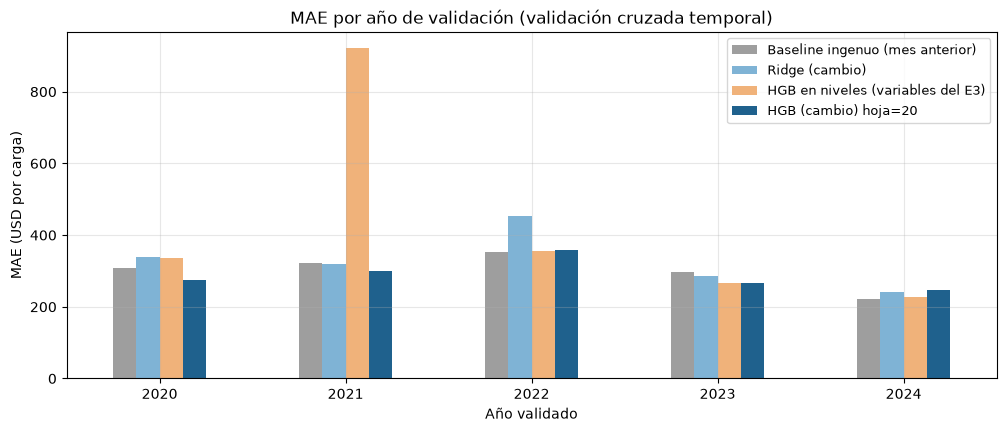

Años en los que el modelo seleccionado le gana al baseline ingenuo: ['2020', '2021', '2023']


modelo,Baseline ingenuo (mes anterior),Ridge (cambio),HGB en niveles (variables del E3),HGB (cambio) hoja=20
anio_validado,,,,
2020,309.00,338.00,336.00,276.00
2021,321.00,320.00,921.00,300.00
2022,354.00,453.00,357.00,358.00
2023,297.00,286.00,268.00,267.00
2024,221.00,241.00,227.00,247.00


In [13]:
por_fold = resultados_cv.pivot(index="anio_validado", columns="modelo", values="MAE")
mostrar = ["Baseline ingenuo (mes anterior)", "Ridge (cambio)", "HGB en niveles (variables del E3)", mejor]
por_fold[mostrar].plot.bar(figsize=(12, 4.5), color=["#9e9e9e", "#7fb3d5", "#f0b27a", "#1f618d"], rot=0)
plt.title("MAE por año de validación (validación cruzada temporal)")
plt.ylabel("MAE (USD por carga)")
plt.xlabel("Año validado")
plt.legend(fontsize=9)
plt.show()

ganador_fold = por_fold[mejor] < por_fold["Baseline ingenuo (mes anterior)"]
print("Años en los que el modelo seleccionado le gana al baseline ingenuo:", list(por_fold.index[ganador_fold]))
por_fold[mostrar].round(0)

**Interpretación.** La validación cruzada confirma lo que esperábamos en el E3: el baseline ingenuo es muy difícil de vencer, con un MAE promedio de 300 USD por carga, y solo el Gradient Boosting que predice el cambio logra superarlo, con 290 USD (alrededor de 3.6% menos) y un RMSE de 422 contra 459 (8% menos). La mejora en RMSE es mayor que en MAE, lo cual indica que el modelo ayuda sobre todo a reducir los errores grandes. Los tres valores de "min_samples_leaf" quedaron prácticamente empatados (entre 290 y 292), por lo que el modelo no es sensible a este parámetro, y elegimos el de menor MAE promedio (hoja = 20).

La comparación de control es muy clara: el mismo algoritmo entrenado en niveles con las variables del E3 tiene un MAE promedio de 422 y en 2021 se dispara a 921, ya que ese año las tarifas subieron a niveles que no existían en el entrenamiento y los árboles no pudieron seguirlas, lo cual justifica haber cambiado el target al cambio porcentual. Por otro lado, la regresión Ridge (328) queda peor que el baseline, lo que sugiere que las relaciones son no lineales.

Sin embargo, el modelo seleccionado no gana todos los años: supera al baseline en 2020 (276 contra 309), 2021 (300 contra 321) y 2023 (267 contra 297), queda prácticamente empatado en 2022 (358 contra 354) y pierde en 2024 (247 contra 221). En 2024 el mercado estuvo muy estable y el baseline tuvo su error más bajo, mientras que el modelo seguía anticipando movimientos estacionales que ese año casi no ocurrieron. Esto nos dice que el modelo aporta más en años con movimiento y menos en años tranquilos.

Con el modelo ya seleccionado lo entrenamos una sola vez con todo el conjunto de desarrollo (2000 a 2024).

In [14]:
modelo_final = crear_modelo_hgb(MEJOR_HOJA)
modelo_final.fit(desarrollo[ENTRADAS], desarrollo[TARGET])
print(f"Entrenado con {len(desarrollo):,} lane-meses de {desarrollo['mes'].min()} a {desarrollo['mes'].max()}")

Entrenado con 11,604 lane-meses de 2000-02 a 2024-12


## 8. Evaluación final en el conjunto de prueba

Esta es la única vez que se usa el conjunto de prueba (enero de 2025 a octubre de 2026). Reportamos cuatro métricas, todas en las mismas filas para el modelo y las referencias:

| Métrica | Qué significa en este problema |
|---|---|
| **MAE** | Cuántos USD por carga se equivoca el pronóstico en promedio; es la métrica principal porque se lee directo en dinero |
| **RMSE** | Igual que el MAE pero castiga más los errores grandes, que son los que más afectan un presupuesto |
| **WAPE** | Error total dividido entre el gasto total real; dice qué porcentaje del gasto en flete se pronosticó mal y permite comparar lanes cortas y largas |
| **R²** | Proporción de la variación explicada; la calculamos en USD y también sobre el cambio mensual, que es lo que realmente predice el modelo |
| **Sesgo** | Promedio de pronóstico menos real; si es negativo, el pronóstico se queda corto |

In [15]:
pred_modelo = a_tarifa(prueba, modelo_final.predict(prueba[ENTRADAS]))
pred_ingenuo = baseline_ingenuo(prueba)
pred_estacional = baseline_estacional(prueba)
pred_media = baseline_media(desarrollo, prueba)
real = prueba["tarifa"].to_numpy()

tabla_prueba = pd.DataFrame({
    "HGB (cambio), modelo seleccionado": metricas(real, pred_modelo),
    "Baseline ingenuo (mes anterior)": metricas(real, pred_ingenuo),
    "Baseline estacional (hace 12 meses)": metricas(real, pred_estacional),
    "Baseline media de entrenamiento": metricas(real, pred_media),
}).T
tabla_prueba["Sesgo (pred - real)"] = [np.mean(p - real) for p in [pred_modelo, pred_ingenuo, pred_estacional, pred_media]]
tabla_prueba

,MAE,RMSE,WAPE,R2,Sesgo (pred - real)
"HGB (cambio), modelo seleccionado",338.36,519.01,0.06,0.97,-60.18
Baseline ingenuo (mes anterior),357.92,556.75,0.06,0.96,-81.85
Baseline estacional (hace 12 meses),755.34,"1,202.52",0.13,0.81,-539.26
Baseline media de entrenamiento,"2,525.05","3,032.75",0.44,-0.18,"-1,197.74"


In [16]:
mejora_mae = 1 - tabla_prueba.loc["HGB (cambio), modelo seleccionado", "MAE"] / tabla_prueba.loc["Baseline ingenuo (mes anterior)", "MAE"]
mejora_rmse = 1 - tabla_prueba.loc["HGB (cambio), modelo seleccionado", "RMSE"] / tabla_prueba.loc["Baseline ingenuo (mes anterior)", "RMSE"]
print(f"Mejora contra el baseline ingenuo: MAE {mejora_mae:.1%} | RMSE {mejora_rmse:.1%}")

# R² sobre el cambio: mide cuánto del movimiento mensual explica el modelo (el baseline predice cambio 0)
cambio_real = prueba[TARGET].to_numpy()
cambio_pred = modelo_final.predict(prueba[ENTRADAS])
print(f"R² sobre el cambio mensual: modelo {r2_score(cambio_real, cambio_pred):.3f} | baseline {r2_score(cambio_real, np.zeros(len(prueba))):.3f}")

Mejora contra el baseline ingenuo: MAE 5.5% | RMSE 6.8%
R² sobre el cambio mensual: modelo 0.177 | baseline -0.013


**Interpretación.** En la prueba el modelo tiene un MAE de 338 USD por carga contra 358 del baseline ingenuo, es decir, se equivoca 5.5% menos, y un RMSE de 519 contra 557 (6.8% menos), con un WAPE de alrededor de 5.9% del gasto real contra 6.2% del baseline. Los otros dos baselines quedan muy lejos (755 y 2,525 de MAE), lo que confirma que la historia reciente de cada lane es la información más valiosa. Los errores son mayores que en la validación cruzada, donde estaban entre 290 y 300, debido a que el periodo de prueba incluye la fuerte subida de 2026, y esto le afecta por igual al modelo y al baseline.

El R² en USD es de 0.97 para el modelo y 0.96 para el baseline, pero este valor es engañoso porque casi toda la variación entre renglones viene de que unas lanes son mucho más caras que otras, algo que cualquier pronóstico que parta del mes anterior ya resuelve. Por eso también medimos el R² sobre el cambio mensual: el modelo explica alrededor de 18% de cuánto sube o baja la tarifa de un mes a otro, mientras que el baseline explica 0%, ya que siempre predice que no habrá cambio. Adicionalmente, los dos pronósticos tienen sesgo negativo (el modelo -60 USD y el baseline -82 USD por carga), es decir, en un periodo de alzas ambos tienden a quedarse cortos, aunque el modelo un poco menos.

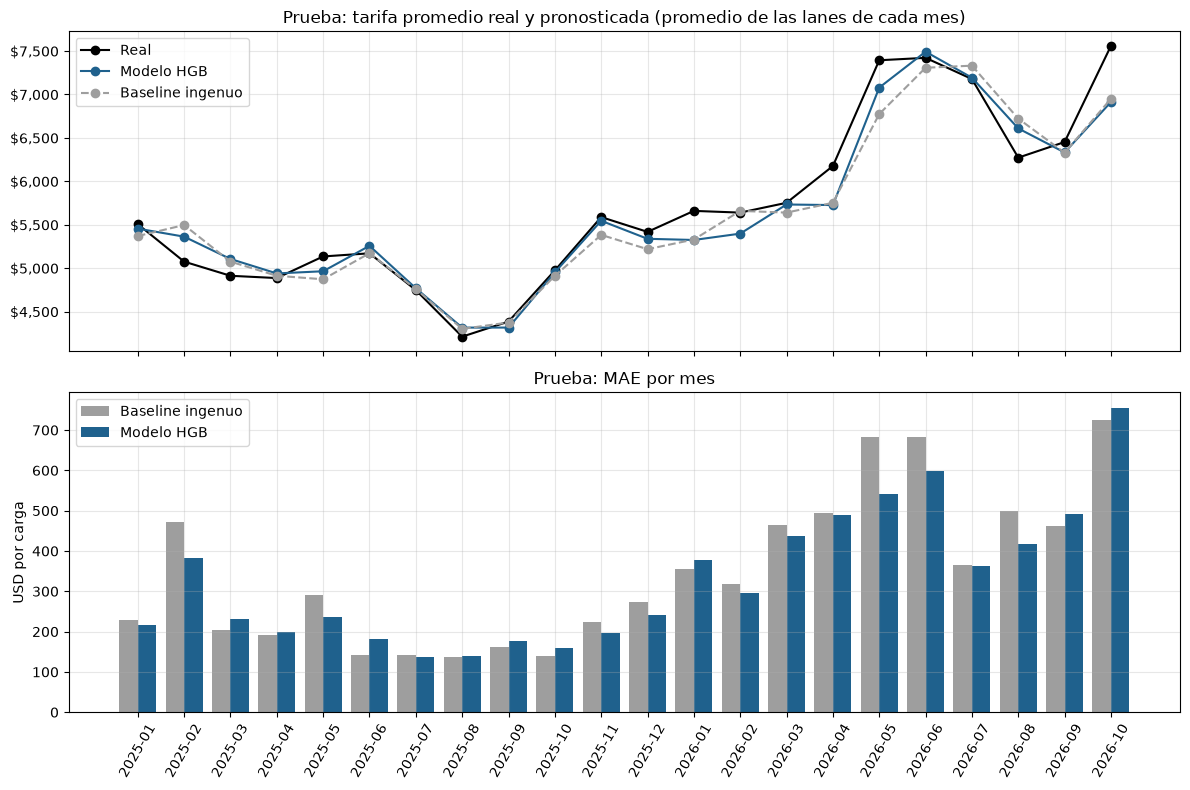

Meses en que el modelo tiene menor MAE que el baseline: 13 de 22


In [17]:
resultados = prueba[["lane", "origin", "destination", "mes", "distancia", "tarifa_lag1", "tarifa"]].copy()
resultados["pred_modelo"] = pred_modelo
resultados["pred_ingenuo"] = pred_ingenuo
resultados["error_modelo"] = (resultados["pred_modelo"] - resultados["tarifa"]).abs()
resultados["error_ingenuo"] = (resultados["pred_ingenuo"] - resultados["tarifa"]).abs()

por_mes = resultados.groupby("mes").agg(real=("tarifa", "mean"), modelo=("pred_modelo", "mean"), ingenuo=("pred_ingenuo", "mean"),
                                        mae_modelo=("error_modelo", "mean"), mae_ingenuo=("error_ingenuo", "mean"))
etiquetas = por_mes.index.astype(str)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(etiquetas, por_mes["real"], marker="o", color="black", label="Real")
axes[0].plot(etiquetas, por_mes["modelo"], marker="o", color="#1f618d", label="Modelo HGB")
axes[0].plot(etiquetas, por_mes["ingenuo"], marker="o", color="#9e9e9e", linestyle="--", label="Baseline ingenuo")
axes[0].set_title("Prueba: tarifa promedio real y pronosticada (promedio de las lanes de cada mes)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axes[0].legend()

x = np.arange(len(por_mes))
axes[1].bar(x - 0.2, por_mes["mae_ingenuo"], width=0.4, color="#9e9e9e", label="Baseline ingenuo")
axes[1].bar(x + 0.2, por_mes["mae_modelo"], width=0.4, color="#1f618d", label="Modelo HGB")
axes[1].set_title("Prueba: MAE por mes")
axes[1].set_ylabel("USD por carga")
axes[1].legend()
plt.xticks(x, etiquetas, rotation=60)
plt.tight_layout()
plt.show()

print(f"Meses en que el modelo tiene menor MAE que el baseline: {(por_mes['mae_modelo'] < por_mes['mae_ingenuo']).sum()} de {len(por_mes)}")

**Interpretación.** En la gráfica superior se ve que el modelo sigue la tendencia general y que en meses de alza como mayo de 2026 se acerca más a la tarifa real que el baseline, aunque siempre por debajo de ella, ya que el modelo tiende a pronosticar cambios más moderados que los reales. En la gráfica inferior el modelo tiene menor MAE en 13 de los 22 meses, y sus mejores meses son los de movimientos fuertes, como febrero de 2025 (383 contra 473), mayo de 2026 (541 contra 684) y junio de 2026 (597 contra 682). Por otro lado, pierde en meses tranquilos como junio de 2025 (182 contra 142) y en octubre de 2026 (756 contra 725), donde la tarifa promedio de las lanes reportadas subió de golpe cerca de 17% y ninguno de los dos pronósticos lo anticipó.

In [18]:
# ¿Dónde funciona mejor o peor? Según el tamaño del cambio real del mes
resultados["cambio_real"] = np.log(resultados["tarifa"] / resultados["tarifa_lag1"])
resultados["tipo_mes"] = pd.cut(resultados["cambio_real"], bins=[-np.inf, -0.05, -0.0001, 0.0001, 0.05, np.inf],
                                labels=["baja > 5%", "baja 0 a 5%", "sin cambio", "sube 0 a 5%", "sube > 5%"])
por_tipo = resultados.groupby("tipo_mes", observed=True).agg(lane_meses=("tarifa", "size"),
                                                             mae_modelo=("error_modelo", "mean"),
                                                             mae_ingenuo=("error_ingenuo", "mean"))
por_tipo["diferencia"] = por_tipo["mae_modelo"] - por_tipo["mae_ingenuo"]

# Y según la distancia de la lane
resultados["distancia_grupo"] = pd.cut(resultados["distancia"], bins=[0, 700, 1400, 2000, np.inf],
                                       labels=["< 700 mi", "700 a 1,400 mi", "1,400 a 2,000 mi", "> 2,000 mi"])
por_distancia = resultados.groupby("distancia_grupo", observed=True).agg(lane_meses=("tarifa", "size"),
                                                                         tarifa_promedio=("tarifa", "mean"),
                                                                         mae_modelo=("error_modelo", "mean"),
                                                                         mae_ingenuo=("error_ingenuo", "mean"))
por_distancia["WAPE_modelo"] = por_distancia["mae_modelo"] / por_distancia["tarifa_promedio"]
por_distancia["WAPE_ingenuo"] = por_distancia["mae_ingenuo"] / por_distancia["tarifa_promedio"]
display(por_tipo)
display(por_distancia)

,lane_meses,mae_modelo,mae_ingenuo,diferencia
tipo_mes,,,,
baja > 5%,243,515.78,582.30,-66.52
baja 0 a 5%,199,199.71,153.23,46.48
sin cambio,242,41.26,0.00,41.26
sube 0 a 5%,243,173.90,152.83,21.07
sube > 5%,319,640.36,742.45,-102.09


,lane_meses,tarifa_promedio,mae_modelo,mae_ingenuo,WAPE_modelo,WAPE_ingenuo
distancia_grupo,,,,,,
< 700 mi,181,"1,964.60",115.93,124.59,0.06,0.06
"700 a 1,400 mi",234,"3,371.61",315.95,363.93,0.09,0.11
"1,400 a 2,000 mi",225,"5,069.11",319.46,342.55,0.06,0.07
"> 2,000 mi",606,"8,058.73",420.46,431.01,0.05,0.05


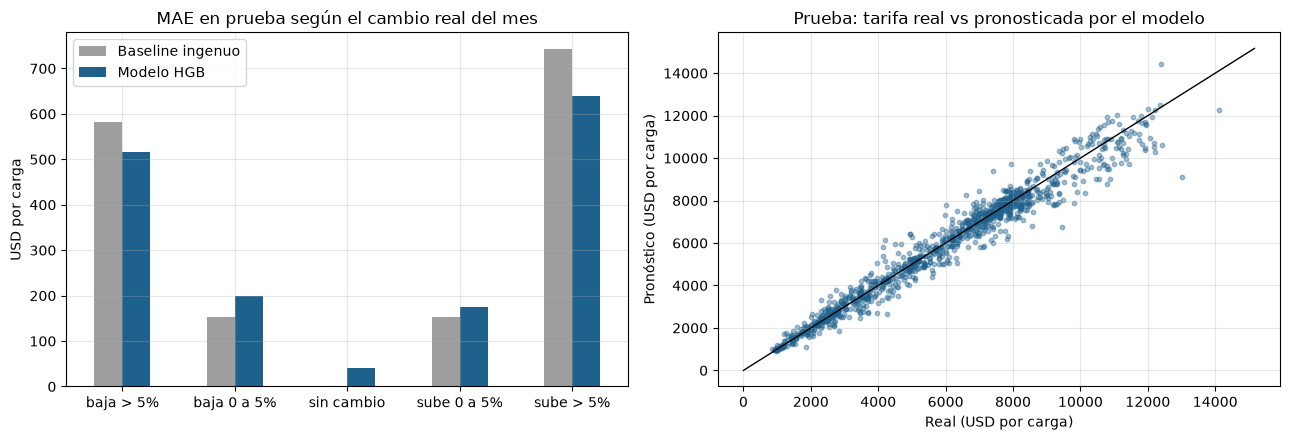

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
por_tipo[["mae_ingenuo", "mae_modelo"]].plot.bar(ax=axes[0], color=["#9e9e9e", "#1f618d"], rot=0)
axes[0].set_title("MAE en prueba según el cambio real del mes")
axes[0].set_ylabel("USD por carga")
axes[0].set_xlabel("")
axes[0].legend(["Baseline ingenuo", "Modelo HGB"])

axes[1].scatter(resultados["tarifa"], resultados["pred_modelo"], s=10, alpha=0.4, color="#1f618d")
limite = [0, resultados[["tarifa", "pred_modelo"]].max().max() * 1.05]
axes[1].plot(limite, limite, color="black", linewidth=1)
axes[1].set_title("Prueba: tarifa real vs pronosticada por el modelo")
axes[1].set_xlabel("Real (USD por carga)")
axes[1].set_ylabel("Pronóstico (USD por carga)")
plt.tight_layout()
plt.show()

**Interpretación.** Las tablas y la gráfica de la izquierda explican con claridad dónde funciona mejor y dónde peor el modelo. En los meses con movimientos de más de 5%, que son 562 de los 1,246 lane-meses de prueba, el modelo reduce el error de forma importante (de 742 a 640 USD en las alzas y de 582 a 516 en las bajas). En cambio, en los meses en que la tarifa no cambia, que en esta prueba son 242 casos (19%), el baseline acierta exacto por definición y el modelo se equivoca en promedio 41 USD, y en los cambios pequeños de 0 a 5% también pierde por entre 21 y 46 USD. En otras palabras, el modelo intercambia un poco de precisión en meses tranquilos por menos error en los meses de movimiento, que son los que más le cuestan al negocio.

Por distancia, el modelo es igual o mejor que el baseline en los cuatro grupos, con la mayor ventaja en las lanes de 700 a 1,400 millas (MAE de 316 contra 364), aunque estas son también las de mayor error relativo (WAPE de 9% contra 5% en las lanes de más de 2,000 millas). La gráfica de la derecha muestra que los pronósticos se concentran alrededor de la diagonal y que los puntos que se alejan más están por debajo de ella en las tarifas altas, lo cual coincide con el sesgo negativo en meses de alza.

Como uno de los usos del pronóstico es decidir si conviene amarrar un contrato, revisamos también si el modelo anticipa la dirección del movimiento.

In [20]:
# Dirección del cambio en los meses con movimiento importante (más de 3%): ¿el modelo anticipa hacia dónde va la tarifa?
movimiento = resultados[resultados["cambio_real"].abs() > 0.03].copy()
movimiento["cambio_predicho"] = np.log(movimiento["pred_modelo"] / movimiento["tarifa_lag1"])
acierto = (np.sign(movimiento["cambio_predicho"]) == np.sign(movimiento["cambio_real"])).mean()
print(f"Lane-meses con movimiento mayor a 3%: {len(movimiento):,} ({len(movimiento) / len(resultados):.0%} de la prueba)")
print(f"El modelo acierta la dirección (sube o baja) en el {acierto:.0%} de esos casos; el baseline siempre predice 'sin cambio'")
print(f"Tamaño promedio del cambio real: {movimiento['cambio_real'].abs().mean():.1%} | del cambio predicho: {movimiento['cambio_predicho'].abs().mean():.1%}")

Lane-meses con movimiento mayor a 3%: 719 (58% de la prueba)
El modelo acierta la dirección (sube o baja) en el 67% de esos casos; el baseline siempre predice 'sin cambio'
Tamaño promedio del cambio real: 10.8% | del cambio predicho: 2.5%


**Interpretación.** En los 719 lane-meses con movimientos de más de 3% (58% de la prueba) el modelo acierta si la tarifa va a subir o bajar en 67% de los casos, algo que el baseline no puede hacer porque siempre predice que no habrá cambio. Sin embargo, el modelo es muy conservador con el tamaño, ya que pronostica cambios de 2.5% en promedio cuando los cambios reales en esos meses son de 10.8%. Esto hace que el modelo sirva más como una señal de dirección (por ejemplo, "esta lane probablemente suba el próximo mes") que como una estimación precisa de cuánto va a subir.

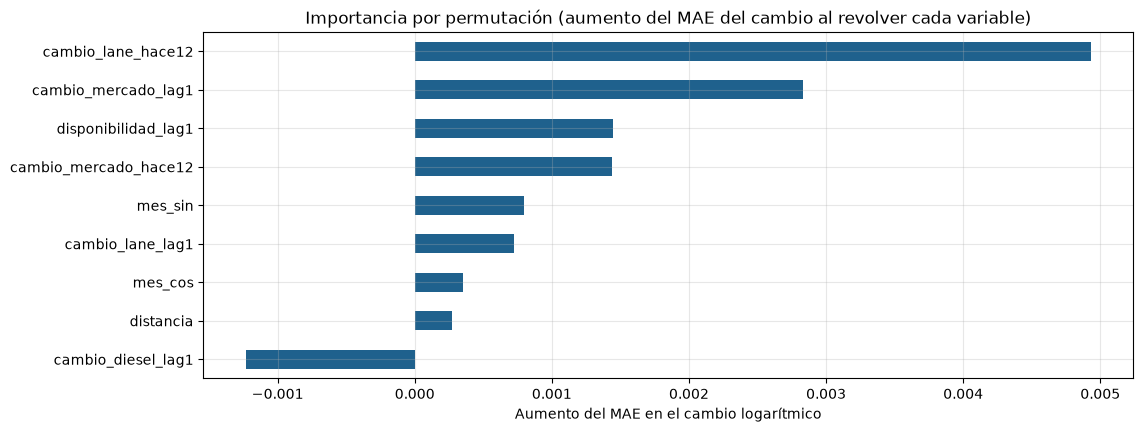

In [21]:
# Importancia de variables por permutación (se calcula después de la evaluación, solo para interpretar)
importancia = permutation_importance(modelo_final, prueba[ENTRADAS], prueba[TARGET], scoring="neg_mean_absolute_error",
                                     n_repeats=10, random_state=SEMILLA)
importancia = pd.Series(importancia.importances_mean, index=ENTRADAS).sort_values()

importancia.plot.barh(color="#1f618d")
plt.title("Importancia por permutación (aumento del MAE del cambio al revolver cada variable)")
plt.xlabel("Aumento del MAE en el cambio logarítmico")
plt.show()

**Interpretación.** La importancia por permutación mide cuánto empeora el error del modelo si revolvemos al azar una variable, y la calculamos después de la evaluación solo para interpretar, sin usarla para tomar decisiones. La variable más importante es "cambio_lane_hace12", es decir, lo que hizo la misma lane en la misma época del año pasado, seguida de "cambio_mercado_lag1", que indica si todo el mercado viene subiendo; después aparecen la disponibilidad de camiones y la estacionalidad del mercado. Esto tiene sentido con el EDA, donde encontramos una estacionalidad moderada pero constante. Por otro lado, "cambio_diesel_lag1" tiene importancia negativa, lo que significa que en la prueba el modelo funcionaría ligeramente mejor sin ella; esto coincide con el E3, donde el diésel casi no se movía con la tarifa mes contra mes (correlación de 0.09), y es un candidato a quitar en una siguiente versión, aunque esa decisión tendría que tomarse con la validación cruzada y no con la prueba.

## 9. Comparación, interpretación y utilidad para el negocio

Para saber si la mejora de 5.5% es real o podría ser suerte, calculamos un intervalo de confianza con **bootstrap por mes**: tomamos al azar, con reemplazo, 22 meses de la prueba, recalculamos la mejora y repetimos 2,000 veces. Remuestreamos meses completos y no renglones, porque las lanes de un mismo mes se mueven juntas y tratarlas como independientes daría un intervalo falsamente angosto.

In [22]:
# Intervalo de confianza de la mejora con bootstrap por mes: se remuestrean MESES completos con reemplazo
rng = np.random.default_rng(SEMILLA)
errores_mes = resultados.groupby("mes").agg(suma_modelo=("error_modelo", "sum"), suma_ingenuo=("error_ingenuo", "sum"),
                                            n=("tarifa", "size"))
mejoras = []
for _ in range(2000):
    muestra = errores_mes.iloc[rng.integers(0, len(errores_mes), len(errores_mes))]
    mejoras.append(1 - muestra["suma_modelo"].sum() / muestra["suma_ingenuo"].sum())
inferior, superior = np.percentile(mejoras, [2.5, 97.5])
print(f"Mejora del MAE contra el baseline: {mejora_mae:.1%} (intervalo de 95%: {inferior:.1%} a {superior:.1%})")
print(f"Proporción de remuestreos en que el modelo es mejor: {np.mean(np.array(mejoras) > 0):.1%}")

Mejora del MAE contra el baseline: 5.5% (intervalo de 95%: 0.0% a 10.1%)
Proporción de remuestreos en que el modelo es mejor: 97.5%


In [23]:
# Traducción a dinero: supongamos un distribuidor que mueve 200 cargas spot al mes en estas lanes
CARGAS_MES = 200
mae_modelo = tabla_prueba.loc["HGB (cambio), modelo seleccionado", "MAE"]
mae_ingenuo = tabla_prueba.loc["Baseline ingenuo (mes anterior)", "MAE"]
print(f"Error absoluto esperado del presupuesto mensual (si los errores no se compensan): "
      f"modelo ${mae_modelo * CARGAS_MES:,.0f} | baseline ${mae_ingenuo * CARGAS_MES:,.0f}")
print(f"Diferencia: ${(mae_ingenuo - mae_modelo) * CARGAS_MES:,.0f} al mes, ${(mae_ingenuo - mae_modelo) * CARGAS_MES * 12:,.0f} al año")

Error absoluto esperado del presupuesto mensual (si los errores no se compensan): modelo $67,671 | baseline $71,585
Diferencia: $3,913 al mes, $46,960 al año


**Interpretación.** El intervalo de 95% para la mejora del MAE va de 0.0% a 10.1% y el modelo es mejor en 97.5% de los remuestreos, por lo que la evidencia apunta a que el modelo sí es mejor que el baseline, aunque el límite inferior queda justo en cero. Con solo 22 meses de prueba no podemos descartar del todo que en otro periodo la ventaja sea muy pequeña, y por eso consideramos que la mejora es **real pero modesta**, lo cual coincide con lo que vimos en la validación cruzada, donde el modelo ganó en 3 de los 5 años.

En términos de negocio, si el distribuidor mueve 200 cargas spot al mes en estas lanes, el error absoluto de su presupuesto de flete sería de alrededor de 67,700 USD al mes con el modelo contra 71,600 con el baseline, una diferencia de cerca de 3,900 USD al mes o 47,000 al año. Este cálculo supone que los errores no se compensan entre lanes, así que es una cota superior y sirve más para dimensionar que como ahorro garantizado.

Los errores tienen consecuencias distintas: cuando el modelo se queda corto (sesgo de -60 USD por carga) el presupuesto queda por debajo del gasto real, lo cual es el error más costoso en meses de alza, mientras que cuando sobreestima en un mes tranquilo la empresa podría amarrar un contrato que no necesitaba. Por lo tanto, consideramos que el modelo es útil como apoyo, en particular para anticipar la dirección del mercado y reducir los errores grandes, pero no lo usaríamos todavía como única base para el presupuesto, sino junto con un margen de seguridad en los meses en que el mercado viene subiendo.

## 10. Ejemplos de predicción y proyección a futuro

### 10.1 Predicciones sobre el conjunto de prueba (con valor real conocido)
Para no escoger los ejemplos a mano, tomamos tres registros de prueba según el error del modelo: uno donde acierta (percentil 10), uno típico (percentil 50) y uno donde falla (percentil 90), entre las lanes que siguen activas en el último mes.

In [24]:
# Regla para elegir sin "escoger a mano": entre las lanes activas en el último mes, tomamos el registro de prueba
# cuyo error del modelo está en el percentil 10 (acierta), 50 (caso típico) y 90 (falla)
activas = base.loc[base["mes"] == ULTIMO_MES, "lane"]
candidatas = resultados[resultados["lane"].isin(activas)].sort_values("error_modelo").reset_index(drop=True)
posiciones = [int(p * (len(candidatas) - 1)) for p in [0.10, 0.50, 0.90]]
ejemplos = candidatas.iloc[posiciones].assign(caso=["acierta (p10)", "típico (p50)", "falla (p90)"])

tabla_ejemplos = ejemplos[["caso", "lane", "mes", "distancia", "tarifa_lag1", "pred_ingenuo", "pred_modelo", "tarifa"]].copy()
tabla_ejemplos["cambio_predicho"] = tabla_ejemplos["pred_modelo"] / tabla_ejemplos["tarifa_lag1"] - 1
tabla_ejemplos["cambio_real"] = tabla_ejemplos["tarifa"] / tabla_ejemplos["tarifa_lag1"] - 1
tabla_ejemplos["error_modelo"] = tabla_ejemplos["pred_modelo"] - tabla_ejemplos["tarifa"]
tabla_ejemplos["error_ingenuo"] = tabla_ejemplos["pred_ingenuo"] - tabla_ejemplos["tarifa"]
tabla_ejemplos.style.format({"distancia": "{:,.0f}", "tarifa_lag1": "${:,.0f}", "pred_ingenuo": "${:,.0f}", "pred_modelo": "${:,.0f}",
                             "tarifa": "${:,.0f}", "cambio_predicho": "{:+.1%}", "cambio_real": "{:+.1%}",
                             "error_modelo": "{:+,.0f}", "error_ingenuo": "{:+,.0f}"}).hide(axis="index")

caso,lane,mes,distancia,tarifa_lag1,pred_ingenuo,pred_modelo,tarifa,cambio_predicho,cambio_real,error_modelo,error_ingenuo
acierta (p10),MEXICO CROSSINGS THROUGH SOUTH TEXAS → DALLAS,2025-04,500,"$1,900","$1,900","$1,883","$1,850",-0.9%,-2.6%,+33,+50
típico (p50),SALINAS-WATSONVILLE CALIFORNIA → NEW YORK,2025-11,"3,000","$8,250","$8,250","$8,414","$8,150",+2.0%,-1.2%,+264,+100
falla (p90),"IMPERIAL, COACHELLA VALLEYS CA, CENTRAL AND WESTERN AZ, MEXICO CROSSINGS THROUGH CALEXICO AND SAN LUIS → ATLANTA",2026-06,"2,100","$6,800","$6,800","$7,235","$8,150",+6.4%,+19.9%,-915,"-1,350"


**Interpretación.** En el caso donde acierta (Mexico Crossings Through South Texas → Dallas, abril de 2025) el modelo anticipó una baja ligera y quedó a 33 USD de la tarifa real, mejor que el baseline (50 USD). En el caso típico (Salinas-Watsonville → New York, noviembre de 2025) el modelo esperaba una subida estacional de 2% y la tarifa bajó 1.2%, por lo que se equivocó por 264 USD, más que el baseline (100 USD), lo cual es un ejemplo de lo que vimos en los meses tranquilos. En el caso donde falla (Imperial, Coachella Valleys → Atlanta, junio de 2026) la tarifa subió casi 20% en un mes; el modelo sí anticipó una subida de 6.4% y se equivocó por 915 USD contra 1,350 del baseline, pero se quedó muy corto, lo que muestra que el modelo no está hecho para anticipar choques de esta magnitud.

### 10.2 Proyección para noviembre de 2026 (sin valor real todavía)
Estas cifras **no** se usan para medir el desempeño, ya que todavía no existe la tarifa real de noviembre. Para producir la proyección agregamos una fila futura por lane activa, calculamos sus variables con la misma función de la sección 3 y reentrenamos el modelo con toda la historia disponible (de 2000 a octubre de 2026) usando la misma configuración elegida en la validación cruzada, ya que en la práctica siempre se usaría la información más reciente.

In [25]:
# 1) Filas futuras: noviembre de 2026 para las lanes con dato en el último mes. La tarifa queda vacía porque no la conocemos
MES_FUTURO = ULTIMO_MES + 1
lanes_activas = base[base["mes"] == ULTIMO_MES][["origin", "destination", "lane", "distancia"]]
futuro = lanes_activas.assign(mes=MES_FUTURO, tarifa=np.nan, disponibilidad=np.nan)

# 2) Mismas variables, calculadas con exactamente la misma función
panel_futuro = crear_variables(pd.concat([base, futuro], ignore_index=True), diesel_mensual)
filas_futuras = panel_futuro[panel_futuro["mes"] == MES_FUTURO].reset_index(drop=True)

# 3) Para producción se reentrena con TODA la historia disponible (desarrollo + prueba) y la misma configuración
modelo_produccion = crear_modelo_hgb(MEJOR_HOJA).fit(datos[ENTRADAS], datos[TARGET])
filas_futuras["pronostico"] = a_tarifa(filas_futuras, modelo_produccion.predict(filas_futuras[ENTRADAS]))
filas_futuras["cambio_pronosticado"] = filas_futuras["pronostico"] / filas_futuras["tarifa_lag1"] - 1

proyeccion = filas_futuras[filas_futuras["lane"].isin(ejemplos["lane"])][["lane", "mes", "tarifa_lag1", "pronostico", "cambio_pronosticado"]]
proyeccion = proyeccion.rename(columns={"tarifa_lag1": f"tarifa real {ULTIMO_MES}", "pronostico": f"estimación {MES_FUTURO} (sin valor real)"})
print(f"Proyección para {MES_FUTURO}: {len(filas_futuras)} lanes | cambio promedio pronosticado {filas_futuras['cambio_pronosticado'].mean():+.1%}")
proyeccion.style.format({f"tarifa real {ULTIMO_MES}": "${:,.0f}", f"estimación {MES_FUTURO} (sin valor real)": "${:,.0f}",
                         "cambio_pronosticado": "{:+.1%}"}).hide(axis="index")

Proyección para 2026-11: 70 lanes | cambio promedio pronosticado +4.8%


lane,mes,tarifa real 2026-10,estimación 2026-11 (sin valor real),cambio_pronosticado
"IMPERIAL, COACHELLA VALLEYS CA, CENTRAL AND WESTERN AZ, MEXICO CROSSINGS THROUGH CALEXICO AND SAN LUIS → ATLANTA",2026-11,"$8,210","$8,500",+3.5%
MEXICO CROSSINGS THROUGH SOUTH TEXAS → DALLAS,2026-11,"$2,125","$2,217",+4.4%
SALINAS-WATSONVILLE CALIFORNIA → NEW YORK,2026-11,"$11,929","$12,403",+4.0%


In [26]:
resultados.drop(columns=["tipo_mes", "distancia_grupo"]).assign(mes=resultados["mes"].astype(str)).to_csv(
    f"{CARPETA_PROC}/predicciones_prueba.csv", index=False)
filas_futuras[["lane", "mes", "tarifa_lag1", "pronostico", "cambio_pronosticado"]].assign(mes=MES_FUTURO.strftime("%Y-%m")).to_csv(
    f"{CARPETA_PROC}/proyeccion_{MES_FUTURO}.csv", index=False)
print("Archivos guardados en", CARPETA_PROC)

Archivos guardados en data/processed


**Interpretación.** Para noviembre de 2026 el modelo proyecta un aumento promedio de 4.8% en las 70 lanes activas, y para las tres lanes de los ejemplos alzas de entre 3.5% y 4.4%. Hay que leer estas cifras con cuidado, ya que vienen justo después de la fuerte subida de octubre y, como vimos, el modelo suele subestimar el tamaño de los movimientos. Las proyecciones de todas las lanes se guardan en "data/processed", junto con las predicciones del conjunto de prueba, para que se puedan revisar o comparar cuando USDA publique los datos reales.

## 11. Conclusiones técnicas

**Qué logramos.** Construimos un prototipo de pronóstico mensual por lane que, con una metodología que respeta el orden del tiempo (pipeline ajustado solo con entrenamiento, validación cruzada temporal por meses y una prueba usada una sola vez), supera al baseline ingenuo, que es una referencia muy exigente en este mercado. En la prueba el MAE bajó de 358 a 338 USD por carga (5.5%) y el RMSE de 557 a 519 (6.8%), el modelo acierta la dirección de 67% de los movimientos de más de 3% y reduce de forma importante el error en los meses de cambios fuertes, que son los que más le cuestan al negocio. También comprobamos que predecir el cambio porcentual en lugar de la tarifa fue la decisión más importante, ya que el mismo algoritmo en niveles fue mucho peor que el baseline.

**Qué no quedó resuelto.** El modelo no anticipa los choques grandes (como la subida de cerca de 17% de octubre de 2026), es conservador con el tamaño de los cambios y es peor que el baseline en meses tranquilos o en lanes que no cambian de precio. Además, seguimos trabajando con tarifas de mercado publicadas por USDA y no con lo que paga la empresa, por lo que la comparación entre spot y contrato y el ahorro real todavía requieren datos internos.

**Límites de confianza.** La mejora es real pero modesta: el intervalo de 95% del bootstrap va de 0.0% a 10.1% y en la validación cruzada el modelo ganó en 3 de 5 años, perdiendo en 2024. Por eso lo vemos como una herramienta de apoyo y no como un reemplazo del criterio del área de compras, y los resultados aplican solo a las 94 lanes con suficiente historia, no a lanes nuevas.

**Qué mejoraríamos con más tiempo o más datos.** Primero, probar quitar el diésel y agregar variables que anticipen choques, como volúmenes de embarque de USDA o índices de capacidad del mercado. Segundo, dar intervalos de predicción (por ejemplo con regresión por cuantiles) en lugar de un solo número, para que el presupuesto incluya un rango. Tercero, combinar el modelo con el baseline según el régimen del mercado, ya que el baseline funciona mejor en meses tranquilos. Por último, con datos internos de la empresa podríamos medir el ahorro real de decidir entre spot y contrato con base en el pronóstico.

## 12. Referencias

- U.S. Department of Agriculture, Agricultural Marketing Service. (2026). *Refrigerated Truck Rates and Availability* [Conjunto de datos]. AgTransport. https://agtransport.usda.gov/d/acar-e3r8
- U.S. Energy Information Administration. (2026). *Weekly U.S. No 2 Diesel Retail Prices* [Conjunto de datos]. https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=EMD_EPD2D_PTE_NUS_DPG&f=W
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3a ed.). OTexts. https://otexts.com/fpp3/